# 04 — Out-of-Sample Backtesting

So far we picked weights and scored them on the **same** history (in-sample).
That can look too good.

A backtest asks: if we only use **past** data to choose weights, how do those portfolios perform **afterward**?

## Concept (read this)

### Look-ahead bias (the main trap)
Using information from the future to make a decision in the past.
Example of cheating: estimate covariance on 2020–2025, then pretend you held that portfolio in 2021.

### Rolling recipe (what we will build)
1. Take the last **N** trading days of returns (**estimation window**, start with N = 252 ≈ 1 year).
2. Compute equal-weight / min-var / max-Sharpe weights using **only** that window.
3. Hold those weights until the next rebalance (start with **monthly** ≈ every 21 trading days).
4. Record the portfolio’s daily returns in that holding period.
5. Slide forward and repeat.

Then compare strategies to each other and to **SPY**, with a simple transaction-cost assumption later.

## 1. Setup

Load prices/returns. We’ll put optimizer helpers in this notebook first, then maybe move them to `src/` later.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from data_loader import DEFAULT_BENCHMARK, DEFAULT_TICKERS, load_or_download

TICKERS = DEFAULT_TICKERS
BENCHMARK = DEFAULT_BENCHMARK
TRADING_DAYS = 252

ESTIMATION_WINDOW = 252   # ~1 year of history to estimate mu / Sigma
REBALANCE_EVERY = 21      # ~1 month between weight updates
RF_ANNUAL = 0.0           # same simplification as before

prices = load_or_download(tickers=TICKERS + [BENCHMARK], refresh=False)
stock_returns = prices[TICKERS].pct_change().dropna()
spy_returns = prices[BENCHMARK].pct_change().dropna()
stock_returns, spy_returns = stock_returns.align(spy_returns, join="inner", axis=0)

print(stock_returns.shape)
print("first:", stock_returns.index.min().date(), "last:", stock_returns.index.max().date())
stock_returns.head()

(1716, 9)
first: 2020-01-03 last: 2026-10-30


,AAPL,MSFT,NVDA,AMZN,KO,WMT,JPM,XOM,JNJ
Date,,,,,,,,,
2020-01-03,-0.009722,-0.012452,-0.016006,-0.012139,-0.005456,-0.008828,-0.013197,-0.008039,-0.011578
2020-01-06,0.007968,0.002585,0.004193,0.014886,-0.000366,-0.002036,-0.000795,0.007678,-0.001247
2020-01-07,-0.004702,-0.009118,0.012107,0.002092,-0.007682,-0.009265,-0.017001,-0.008184,0.006107
2020-01-08,0.016086,0.015928,0.001875,-0.007809,0.001843,-0.003432,0.007801,-0.015080,-0.000138
2020-01-09,0.021241,0.012493,0.010982,0.004799,0.018216,0.010330,0.003651,0.007656,0.002966


## 2. Weight functions (one estimation window → one weight vector)

These must use **only** the returns you pass in (the past window). No peeking at later rows.

In [10]:
# TODO: equal_weight, min_variance_weights, max_sharpe_weights helpers

def equal_weight(n):
    return np.repeat(1/n, n)

def min_variance_weights(returns: pd.DataFrame) -> np.ndarray:
    """Long-only min-var using ONLY the provided return window"""
    cov = returns.cov().values
    n = returns.shape[1]

    def obj(w):
        return float(w @ cov @ w)

    res = minimize(obj, equal_weight(n), method='SLSQP',
        bounds=tuple((0.0,1.0) for _ in range(n)),
        constraints={"type": "eq", "fun": lambda w: np.sum(w) - 1.0},
        options={"ftol": 1e-14, "maxiter": 1000},
    )

    w = np.clip(res.x, 0, None)
    return w / w.sum()

def max_sharpe_weights(returns: pd.DataFrame, trading_days=252, rf=0.0) -> np.ndarray:
    """Long-only max-Sharpe using ONLY the provided return window"""
    mu = returns.mean().values
    cov = returns.cov().values
    n = returns.shape[1]

    def neg_sharpe(w):
        ann_ret = trading_days * float(w @ mu)
        ann_vol = np.sqrt(trading_days * float(w @ cov @ w))
        if ann_vol <= 1e-12:
            return 1e6
        return -((ann_ret - rf) / ann_vol)

    res = minimize(neg_sharpe, equal_weight(n), method='SLSQP',
        bounds=tuple((0.0,1.0) for _ in range(n)),
        constraints={"type": "eq", "fun": lambda w: np.sum(w) - 1.0},
        options={"ftol": 1e-14, "maxiter": 1000},
    )

    w = np.clip(res.x, 0, None)
    return w / w.sum()

# Smoke test on the first year only (should sum to 1)
window = stock_returns.iloc[:ESTIMATION_WINDOW]
print("EW sum:", equal_weight(len(TICKERS)).sum())
print("min-var sum:", min_variance_weights(window).sum().round(6))
print("max-sharpe sum:", max_sharpe_weights(window, TRADING_DAYS, RF_ANNUAL).sum().round(6))
print("min-var weights:", dict(zip(TICKERS, min_variance_weights(window).round(3))))

EW sum: 1.0
min-var sum: 1.0
max-sharpe sum: 1.0
min-var weights: {'AAPL': np.float64(0.0), 'MSFT': np.float64(0.0), 'NVDA': np.float64(0.0), 'AMZN': np.float64(0.193), 'KO': np.float64(0.19), 'WMT': np.float64(0.328), 'JPM': np.float64(0.0), 'XOM': np.float64(0.0), 'JNJ': np.float64(0.288)}


## 3. Rolling backtest engine

Walk forward: estimate → hold → rebalance → repeat.

In [11]:
# TODO: backtest loop

def backtest(returns: pd.DataFrame, weight_fn, estimation_window=252, rebalance_every=21):
    """
    Walk-forward backtest.
    weight_fn(window_df) -> 1d array of weights aligned to returns.columns
    """
    dates = returns.index
    n = returns.shape[1]
    portfolio_returns = []

    # first day we can trade after having a full estimation window
    i = estimation_window
    while i < len(dates):
        est = returns.iloc[i - estimation_window : i]   # PAST only
        w = np.asarray(weight_fn(est), dtype=float)
        w = w / w.sum()

        hold_end = min(i + rebalance_every, len(dates))
        hold = returns.iloc[i:hold_end]                 # FUTURE relative to estimate
        # daily portfolio return = weighted sum of asset returns
        pr = hold.values @ w
        portfolio_returns.append(pd.Series(pr, index=hold.index))

        i = hold_end

    return pd.concat(portfolio_returns).sort_index()


bt_ew = backtest(
    stock_returns,
    lambda r: equal_weight(r.shape[1]),
    ESTIMATION_WINDOW,
    REBALANCE_EVERY,
)
bt_min = backtest(
    stock_returns,
    min_variance_weights,
    ESTIMATION_WINDOW,
    REBALANCE_EVERY,
)
bt_sharpe = backtest(
    stock_returns,
    lambda r: max_sharpe_weights(r, TRADING_DAYS, RF_ANNUAL),
    ESTIMATION_WINDOW,
    REBALANCE_EVERY,
)

# Align SPY to the same out-of-sample dates
bt_spy = spy_returns.reindex(bt_ew.index)

print("OOS days:", len(bt_ew))
print("OOS start:", bt_ew.index.min().date(), "end:", bt_ew.index.max().date())
print(bt_ew.head())

OOS days: 1464
OOS start: 2021-01-04 end: 2026-10-30
Date
2021-01-04   -0.010305
2021-01-05    0.010513
2021-01-06   -0.009681
2021-01-07    0.017878
2021-01-08    0.005403
dtype: float64


## 4. Results: growth chart + scorecard vs SPY

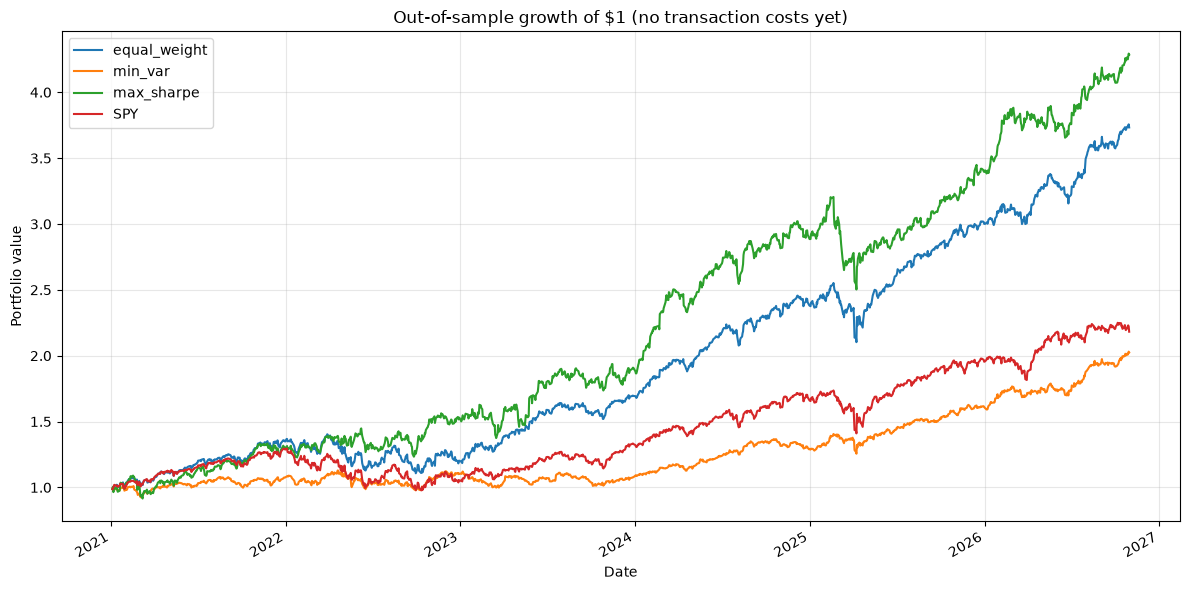

,ann_return,ann_vol,sharpe,max_drawdown
equal_weight,23.98%,16.13%,1.49,-21.09%
min_var,12.87%,12.02%,1.07,-13.37%
max_sharpe,26.89%,19.14%,1.40,-21.92%
SPY,14.81%,16.58%,0.89,-24.50%


In [12]:
# TODO: compare strategies
def performance_metrics(returns: pd.Series, trading_days: int = 252) -> dict:
    r = returns.dropna()
    ann_return = r.mean() * trading_days
    ann_vol = r.std() * np.sqrt(trading_days)
    sharpe = ann_return / ann_vol if ann_vol > 0 else np.nan
    wealth = (1 + r).cumprod()
    max_drawdown = (wealth / wealth.cummax() - 1).min()
    return {
        "ann_return": ann_return,
        "ann_vol": ann_vol,
        "sharpe": sharpe,
        "max_drawdown": max_drawdown,
    }

results = pd.DataFrame({
    "equal_weight": bt_ew,
    "min_var": bt_min,
    "max_sharpe": bt_sharpe,
    "SPY": bt_spy,
}).dropna()

wealth = (1 + results).cumprod()

ax = wealth.plot(figsize=(12, 6), title="Out-of-sample growth of $1 (no transaction costs yet)")
ax.set_ylabel("Portfolio value")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

scorecard = pd.DataFrame({col: performance_metrics(results[col]) for col in results.columns}).T
scorecard.style.format({
    "ann_return": "{:.2%}",
    "ann_vol": "{:.2%}",
    "sharpe": "{:.2f}",
    "max_drawdown": "{:.2%}",
})